In [1]:
import numpy as np
import pandas as pd
import optuna
from catboost import CatBoostRegressor
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from catboost import Pool
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner
import matplotlib.pyplot as plt
from optuna.visualization import matplotlib as ovm

/home/sophia0805/projects/haggle/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv("train.csv")

X = df.drop(columns=["project_id", "hours_spent", "log_hours", "hours_bucket"])
y = df["hours_spent"]
y_log = np.log1p(y)

print(f"Rows: {len(df):,}")
print(f"Features: {X.shape[1]}")

Rows: 4,500
Features: 69


In [3]:
PRIOR_MAP = {"0": 0, "1-2": 1, "3-5": 2, "6+": 3}
AGE_MAP = {"<1": 0, "1-2": 1, "3-5": 2, "6+": 3}
BOOL_MAP = {True: 1.0, False: 0.0, "True": 1.0, "False": 0.0}

CAT_COLS = [
    "primary_language",
    "framework",
    "hosting_type",
    "commit_cadence",
    "project_category",
]

BOOL_COLS = [
    "uses_game_engine", "has_tests", "has_ci_config", "has_dockerfile",
    "has_backend", "has_database", "has_custom_art",
    "readme_has_install_instructions", "has_license", "has_docs_folder",
    "url_is_live", "is_mobile_responsive", "has_custom_domain",
    "is_multiplayer", "mentions_ai_api", "is_clone_or_tutorial",
    "is_forked_from_template",
]


def clean_features(X):
    X = X.copy()
    X["author_prior_projects"] = X["author_prior_projects"].astype(str).map(PRIOR_MAP)
    X["author_account_age_years"] = X["author_account_age_years"].astype(str).map(AGE_MAP)

    for column in BOOL_COLS:
        if column in X.columns:
            X[column] = X[column].map(BOOL_MAP)

    for column in CAT_COLS:
        X[column] = X[column].fillna("missing").astype(str)

    return X


def divide(numerator, denominator):
    return numerator / denominator.replace(0, np.nan)


def add_features(X):
    X = clean_features(X)
    X = X.copy()

    X["lines_per_active_day"] = divide(X.lines_added_total, X.active_commit_days)
    X["loc_per_commit"] = divide(X.lines_of_code, X.num_commits)
    X["commits_per_active_day"] = divide(X.num_commits, X.active_commit_days)
    X["active_frac"] = divide(X.active_commit_days, X.project_span_days + 1)
    X["total_lines_touched"] = np.log1p(X.lines_added_total + X.lines_deleted_total)
    X["biggest_commit_share"] = divide(X.max_lines_in_one_commit, X.lines_added_total)
    X["bulk_upload"] = (X.pct_code_in_first_commit > 0.8).astype(float).where(
        X.pct_code_in_first_commit.notna()
    )
    X["few_commits"] = (X.num_commits <= 3).astype(float).where(X.num_commits.notna())
    X["no_git"] = X.num_commits.isna().astype(float)
    X["n_assets"] = X[[
        "num_image_files", "num_audio_files", "num_3d_model_files", "num_font_files"
    ]].sum(axis=1, min_count=1)
    X["readme_richness"] = X[[
        "readme_num_headings", "readme_num_images", "readme_num_code_blocks"
    ]].sum(axis=1, min_count=1)
    X["loc_x_days"] = np.log1p(X.lines_of_code) * np.log1p(X.active_commit_days)
    X["loc_template_adj"] = (
        np.log1p(X.lines_of_code)
        * (1 - 0.5 * X.is_forked_from_template.fillna(0))
    )

    return X


Xf = add_features(X)

In [4]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_splits = list(cv.split(Xf, df["hours_bucket"]))

FINAL_LR = 0.03 #from earlier tests
search_splits = cv_splits[:3]

pools = []
for tr, va in search_splits:
    tr_a, tr_b = train_test_split(tr, test_size=0.15, random_state=0, stratify=df["hours_bucket"].values[tr])
    pools.append((
        Pool(Xf.iloc[tr_a], y_log.iloc[tr_a], cat_features=CAT_COLS),
        Pool(Xf.iloc[tr_b], y_log.iloc[tr_b], cat_features=CAT_COLS),
        Pool(Xf.iloc[va], cat_features=CAT_COLS),
        y_log.values[va],
    ))

def objective(trial):
    params = dict(
        iterations=5000,
        learning_rate=FINAL_LR,
        depth=trial.suggest_int("depth", 4, 8),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1, 30, log=True),
        rsm=trial.suggest_float("rsm", 0.3, 1.0),
        random_strength=trial.suggest_float("random_strength", 0.0, 3.0),
        bootstrap_type="Bayesian",
        bagging_temperature=trial.suggest_float("bagging_temperature", 0.0, 2.0),
        max_ctr_complexity=1,
        loss_function="RMSE",
        random_seed=42,
        thread_count=-1,
        allow_writing_files=False,
        verbose=0,
    )
    scores, iters = [], []
    for step, (p_tr, p_es, p_va, y_va) in enumerate(pools):
        m = CatBoostRegressor(**params)
        m.fit(p_tr, eval_set=p_es, early_stopping_rounds=100, use_best_model=True)
        scores.append(root_mean_squared_error(y_va, m.predict(p_va)))
        iters.append(m.get_best_iteration())
        trial.report(float(np.mean(scores)), step)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("median_iters", int(np.median(iters)))
    return float(np.mean(scores))


In [5]:
study = optuna.create_study(
    direction="minimize",
    study_name="catboost_hours",
    storage="sqlite:///optuna_cb.db",
    load_if_exists=True,
    sampler=TPESampler(seed=42, multivariate=True, n_startup_trials=10),
    pruner=MedianPruner(n_startup_trials=8, n_warmup_steps=0),
)

study.enqueue_trial({"depth": 6, "l2_leaf_reg": 5, "rsm": 0.5,
                     "random_strength": 1.0, "bagging_temperature": 1.0})

study.optimize(objective, n_trials=60, timeout=3600, show_progress_bar=True)

print("Best:", study.best_value, study.best_params,
      "trees @ lr", FINAL_LR, "=", study.best_trial.user_attrs["median_iters"])

[I 2026-11-26 09:25:30,091] Using an existing study with `study_name='catboost_hours'` instead of creating a new one.
Best trial: 1. Best value: 0.668529:   2%|▏         | 1/60 [00:20<20:15, 20.60s/it, 20.58/3600 seconds]

[I 2026-11-26 09:25:50,731] Trial 1 finished with value: 0.6685293570979072 and parameters: {'depth': 6, 'l2_leaf_reg': 5, 'rsm': 0.5, 'random_strength': 1.0, 'bagging_temperature': 1.0}. Best is trial 1 with value: 0.6685293570979072.


Best trial: 1. Best value: 0.668529:   3%|▎         | 2/60 [00:53<27:10, 28.12s/it, 53.97/3600 seconds]

[I 2026-11-26 09:26:24,117] Trial 2 finished with value: 0.6704095516583853 and parameters: {'depth': 5, 'l2_leaf_reg': 25.369990766817715, 'rsm': 0.8123957592679836, 'random_strength': 1.7959754525911098, 'bagging_temperature': 0.31203728088487304}. Best is trial 1 with value: 0.6685293570979072.


Best trial: 1. Best value: 0.668529:   5%|▌         | 3/60 [01:15<23:49, 25.08s/it, 75.45/3600 seconds]

[I 2026-11-26 09:26:45,590] Trial 3 finished with value: 0.6734756513959468 and parameters: {'depth': 4, 'l2_leaf_reg': 1.218418650222176, 'rsm': 0.9063233020424546, 'random_strength': 1.8033450352296265, 'bagging_temperature': 1.416145155592091}. Best is trial 1 with value: 0.6685293570979072.


... (110 outputs left out)

Best trial: 12. Best value: 0.662817:  98%|█████████▊| 59/60 [23:13<00:25, 25.12s/it, 1393.28/3600 seconds]

[I 2026-11-26 09:48:43,430] Trial 59 pruned. 


Best trial: 12. Best value: 0.662817: 100%|██████████| 60/60 [23:33<00:00, 23.56s/it, 1413.78/3600 seconds]

[I 2026-11-26 09:49:03,929] Trial 60 pruned. 
Best: 0.6628173366758702 {'depth': 8, 'l2_leaf_reg': 2.626524302449683, 'rsm': 0.37830041083102983, 'random_strength': 2.9169150078877735, 'bagging_temperature': 0.8179518615465418} trees @ lr 0.03 = 927


/tmp/ipykernel_67343/954698981.py:1: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ovm.plot_optimization_history(study); plt.show()


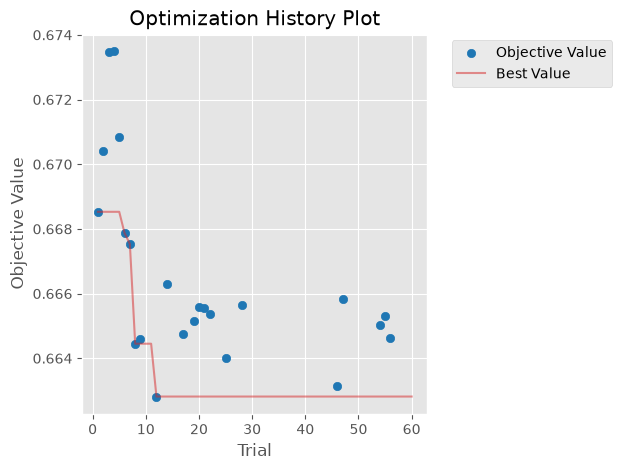

/tmp/ipykernel_67343/954698981.py:2: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ovm.plot_param_importances(study); plt.show()


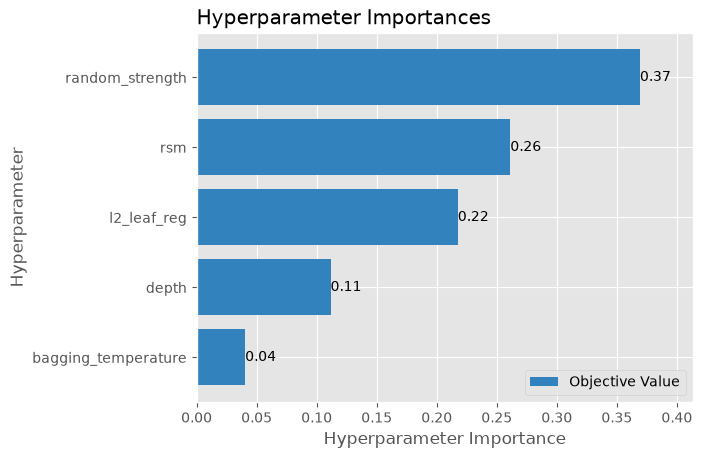

/tmp/ipykernel_67343/954698981.py:3: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  ovm.plot_slice(study, params=["depth", "l2_leaf_reg", "rsm"]); plt.show()


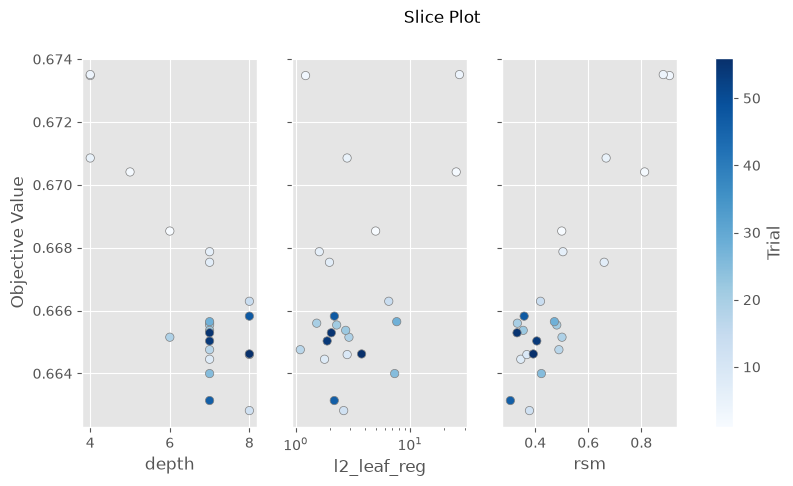

/tmp/ipykernel_67343/954698981.py:4: ExperimentalWarning: optuna.visualization.matplotlib._contour.plot_contour is experimental (supported from v2.2.0). The interface can change in the future.
  ovm.plot_contour(study, params=["depth", "l2_leaf_reg"]); plt.show()


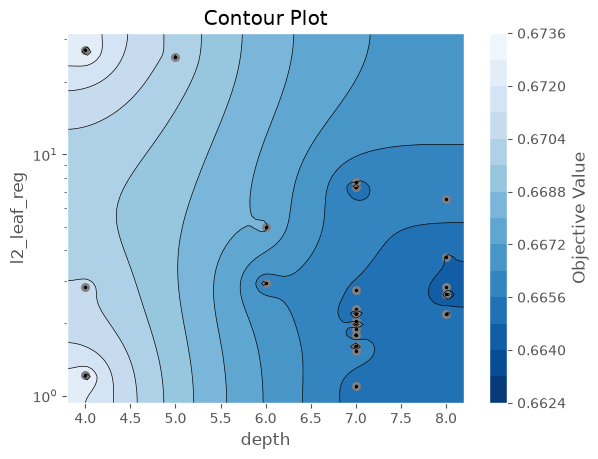

In [6]:
ovm.plot_optimization_history(study); plt.show()
ovm.plot_param_importances(study); plt.show()
ovm.plot_slice(study, params=["depth", "l2_leaf_reg", "rsm"]); plt.show()
ovm.plot_contour(study, params=["depth", "l2_leaf_reg"]); plt.show()

In [7]:
n_iters = int(study.best_trial.user_attrs["median_iters"] * 1.1)

final_params = study.best_params.copy()
final_params.update({
    "cat_features": CAT_COLS,
    "iterations": n_iters,
    "learning_rate": FINAL_LR,
    "bootstrap_type": "Bayesian",
    "loss_function": "RMSE",
    "random_seed": 42,
    "allow_writing_files": False,
    "verbose": 200,
})
print(final_params)

final_model = CatBoostRegressor(**final_params)
final_model.fit(Xf, y_log)
final_model.save_model("model.cbm")

pd.Series(Xf.columns).to_csv("feature_columns.csv", index=False)

{'depth': 8, 'l2_leaf_reg': 2.626524302449683, 'rsm': 0.37830041083102983, 'random_strength': 2.9169150078877735, 'bagging_temperature': 0.8179518615465418, 'cat_features': ['primary_language', 'framework', 'hosting_type', 'commit_cadence', 'project_category'], 'iterations': 1019, 'learning_rate': 0.03, 'bootstrap_type': 'Bayesian', 'loss_function': 'RMSE', 'random_seed': 42, 'allow_writing_files': False, 'verbose': 200}
0:	learn: 0.9535096	total: 28.2ms	remaining: 28.7s
200:	learn: 0.6083982	total: 4.26s	remaining: 17.3s
400:	learn: 0.5208631	total: 8.28s	remaining: 12.8s
600:	learn: 0.4442196	total: 12.2s	remaining: 8.52s
800:	learn: 0.3827960	total: 16.2s	remaining: 4.41s
1000:	learn: 0.3302407	total: 20.2s	remaining: 364ms
1018:	learn: 0.3258007	total: 20.5s	remaining: 0us
